# DSCI 552 – Homework 8

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

### 1(a) Breast Cancer Wisconsin (Diagnostic) Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans, SpectralClustering

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load the Breast Cancer Wisconsin (Diagnostic) dataset

df = pd.read_csv("wdbc.data", header=None)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Separate features and labels

X = df.iloc[:, 2:].values
y = (df.iloc[:, 1] == "M").astype(int).values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class distribution:", np.bincount(y))

X shape: (569, 30)
y shape: (569,)
Class distribution: [357 212]


### 1(b) Monte Carlo Simulation

Throughout Problem 1, **Malignant (M) = 1 is the positive class** and Benign (B) = 0 is the negative class; precision, recall, F1-score and AUC are all computed for the malignant class.

Each Monte Carlo run `r = 0, 1, ..., 29` uses a stratified split with `random_state=r`, so exactly 20% of the positive class and 20% of the negative class are held out as the test set.

The single-run results (ROC curves and confusion matrices) shown before each Monte Carlo loop use the split of **Monte Carlo run 1 (`random_state=0`)** together with the same CV / initialization seeds as the loop, so they are exactly the results of one of the M runs.

#### i. Supervised Learning

In [4]:
# Split the dataset into training and testing sets
# Preserve the class distribution using stratified sampling

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=0   # same split as Monte Carlo run 1
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("Training class distribution:", np.bincount(y_train))
print("Testing class distribution:", np.bincount(y_test))

Training set: (455, 30)
Testing set: (114, 30)
Training class distribution: [285 170]
Testing class distribution: [72 42]


##### L1-Penalized SVM with 5-Fold Cross-Validation

In [5]:
# Build a pipeline with normalization and L1-penalized SVM
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        penalty="l1",
        dual=False,
        max_iter=20000,
        random_state=42
    ))
])

# Define the parameter grid
param_grid = {
    "svm__C": np.logspace(-3, 3, 13)
}

# 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Train the model
grid_search.fit(X_train, y_train)

# Best model and parameters
best_svm = grid_search.best_estimator_

print("Best C:", grid_search.best_params_["svm__C"])
print("Best CV Accuracy:", grid_search.best_score_)

Best C: 0.03162277660168379
Best CV Accuracy: 0.9824175824175825


##### Model Evaluation: Accuracy, Precision, Recall, F1-score, and AUC

In [6]:
# Evaluate the best SVM on training and testing sets

def evaluate_model(model, X_data, y_true):
    y_pred = model.predict(X_data)
    y_score = model.decision_function(X_data)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_true, y_score)
    }

train_metrics = evaluate_model(best_svm, X_train, y_train)
test_metrics = evaluate_model(best_svm, X_test, y_test)

results_df = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Training", "Testing"]
)

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9868,0.994,0.9706,0.9821,0.9955
Testing,0.9386,0.907,0.9286,0.9176,0.9914


##### ROC Curves and Confusion Matrices (Monte Carlo run 1)

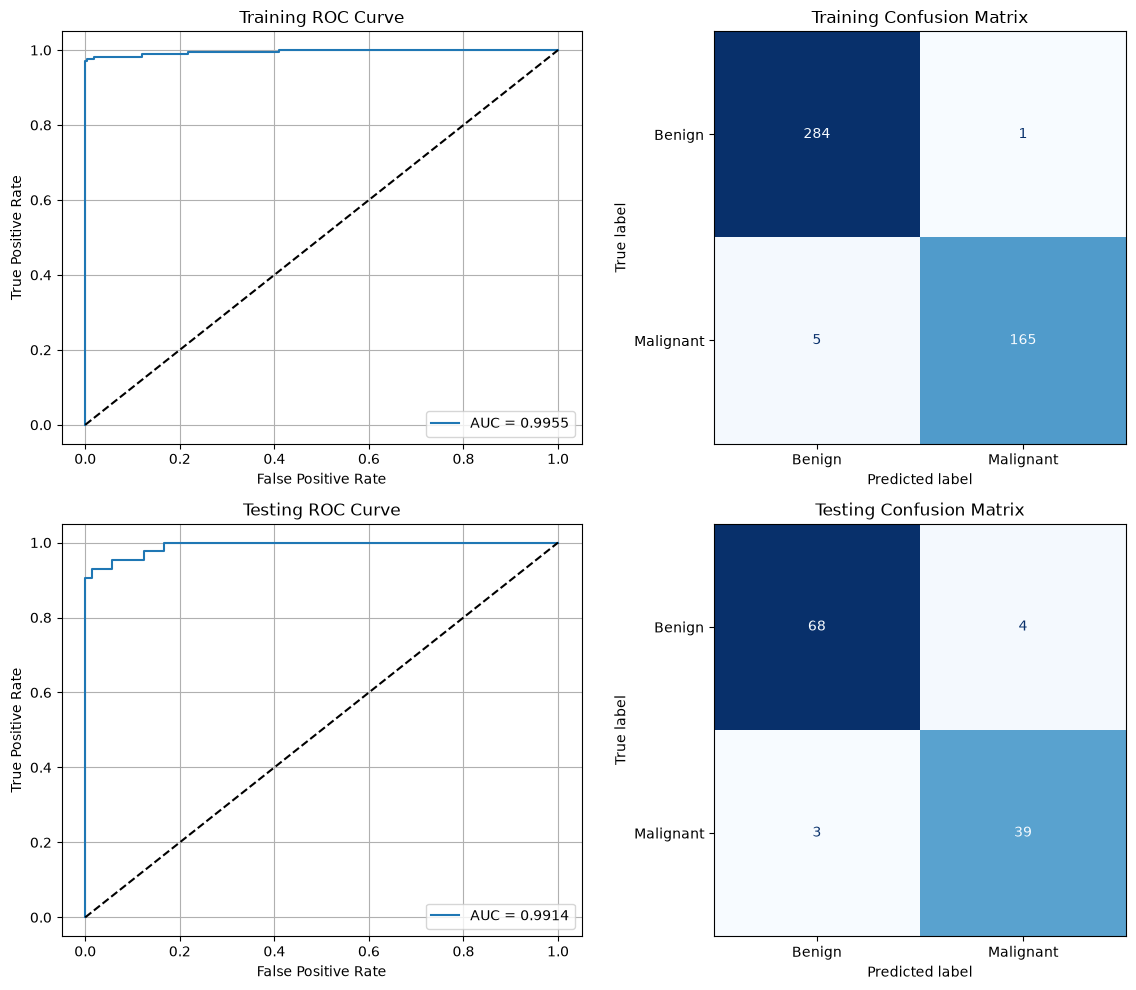

In [7]:
# ROC curves and confusion matrices

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (name, X_data, y_data) in enumerate([
    ("Training", X_train, y_train),
    ("Testing", X_test, y_test)
]):
    y_pred = best_svm.predict(X_data)
    y_score = best_svm.decision_function(X_data)

    # ROC curve
    fpr, tpr, _ = roc_curve(y_data, y_score)
    auc_value = roc_auc_score(y_data, y_score)

    axes[i, 0].plot(
        fpr, tpr,
        label=f"AUC = {auc_value:.4f}"
    )
    axes[i, 0].plot([0, 1], [0, 1], "k--")
    axes[i, 0].set_title(f"{name} ROC Curve")
    axes[i, 0].set_xlabel("False Positive Rate")
    axes[i, 0].set_ylabel("True Positive Rate")
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    # Confusion matrix
    cm = confusion_matrix(y_data, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(ax=axes[i, 1], cmap="Blues", colorbar=False)
    axes[i, 1].set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

##### Monte Carlo Simulation (30 Runs)

In [8]:
# Monte Carlo Simulation: 30 runs

M = 30

supervised_train_results = []
supervised_test_results = []
supervised_best_C = []

for i in range(M):

    # Random stratified train/test split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=i
    )

    # Build SVM pipeline
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])

    # 5-fold cross-validation
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=i
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__C": np.logspace(-3, 3, 13)
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_tr, y_tr)

    best_model = grid.best_estimator_

    # Store training and testing metrics
    supervised_train_results.append(
        evaluate_model(best_model, X_tr, y_tr)
    )

    supervised_test_results.append(
        evaluate_model(best_model, X_te, y_te)
    )

    supervised_best_C.append(
        grid.best_params_["svm__C"]
    )

    print(f"Run {i+1}/{M} completed")

# Calculate average metrics
supervised_train_avg = pd.DataFrame(
    supervised_train_results
).mean()

supervised_test_avg = pd.DataFrame(
    supervised_test_results
).mean()

supervised_summary = pd.DataFrame({
    "Training": supervised_train_avg,
    "Testing": supervised_test_avg
}).T

print("\nAverage Performance over 30 Runs:")
display(supervised_summary.round(4))

# Penalty parameters selected by 5-fold CV in the 30 runs
print("\nPenalty parameter C selected by 5-fold CV (count over 30 runs):")
print(pd.Series(supervised_best_C).value_counts().sort_index().rename("count"))

# Run 1 is the single run shown above
print("\nRun 1 test metrics:",
      {k: round(v, 4) for k, v in supervised_test_results[0].items()})

Run 1/30 completed


Run 2/30 completed


Run 3/30 completed


Run 4/30 completed


Run 5/30 completed


Run 6/30 completed


... (22 outputs left out)

Run 29/30 completed


Run 30/30 completed

Average Performance over 30 Runs:


,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9855,0.9912,0.9698,0.9804,0.9972
Testing,0.9673,0.9711,0.9397,0.9547,0.9932



Penalty parameter C selected by 5-fold CV (count over 30 runs):
0.031623      7
0.100000     11
0.316228      8
1.000000      3
31.622777     1
Name: count, dtype: int64

Run 1 test metrics: {'Accuracy': 0.9386, 'Precision': 0.907, 'Recall': 0.9286, 'F1-score': 0.9176, 'AUC': 0.9914}


##### Results and Discussion

The L1-penalized SVM was evaluated using 30 Monte Carlo
simulations with stratified train-test splits. The penalty
parameter C was selected using 5-fold cross-validation.

The average training accuracy was 98.55%, while the average
testing accuracy was 96.73%. The average testing F1-score
was 0.9547, and the average testing AUC was 0.9932.

These results indicate that the supervised SVM achieves
strong classification performance. The small difference
between training and testing accuracy suggests good
generalization, with limited evidence of overfitting.

#### ii. Semi-Supervised Learning / Self-training

##### Splitting Labeled and Unlabeled Data

In [9]:
# Split training data into labeled and unlabeled sets
# Preserve the class distribution

X_labeled, X_unlabeled, y_labeled, y_unlabeled_true = train_test_split(
    X_train,
    y_train,
    test_size=0.5,
    stratify=y_train,
    random_state=0   # same as Monte Carlo run 1
)

print("Labeled data:", X_labeled.shape)
print("Unlabeled data:", X_unlabeled.shape)

print("Labeled class distribution:", np.bincount(y_labeled))
print("Unlabeled class distribution:", np.bincount(y_unlabeled_true))

Labeled data: (227, 30)
Unlabeled data: (228, 30)
Labeled class distribution: [142  85]
Unlabeled class distribution: [143  85]


##### Initial L1-Penalized SVM with 5-Fold Cross-Validation

In [10]:
# Build the initial L1-penalized SVM

semi_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        penalty="l1",
        dual=False,
        max_iter=20000,
        random_state=42
    ))
])

# Parameter grid
semi_param_grid = {
    "svm__C": np.logspace(-3, 3, 13)
}

# 5-fold cross-validation
semi_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

semi_grid = GridSearchCV(
    estimator=semi_pipeline,
    param_grid=semi_param_grid,
    cv=semi_cv,
    scoring="accuracy",
    n_jobs=-1
)

# Train using labeled data only
semi_grid.fit(X_labeled, y_labeled)

initial_semi_svm = semi_grid.best_estimator_

print("Best C:", semi_grid.best_params_["svm__C"])
print("Best CV Accuracy:", semi_grid.best_score_)
print("Initial labeled samples:", len(y_labeled))
print("Remaining unlabeled samples:", len(X_unlabeled))

Best C: 0.1
Best CV Accuracy: 0.9557487922705313
Initial labeled samples: 227
Remaining unlabeled samples: 228


##### Iterative Self-training with Pseudo-labeling

At each iteration the unlabeled point **farthest from the decision boundary** is selected. For a linear SVM the distance of a point $x$ to the hyperplane is $|w^\top x + b| / \|w\|$; since $\|w\|$ is the same for all candidate points of a given SVM, the point with the largest $|$decision_function$|$ is the farthest one. The SVM labels that point (its true label is ignored), the point is moved to the labeled set, and the SVM is retrained. This continues until no unlabeled data remain.

The penalty parameter $C$ is chosen once by 5-fold CV on the initially labeled data (step A) and kept fixed while the SVM is retrained in step B.

In [11]:
# Iterative self-training

X_labeled_current = X_labeled.copy()
y_labeled_current = y_labeled.copy()
X_unlabeled_current = X_unlabeled.copy()

semi_model = initial_semi_svm

# Keep the selected penalty parameter from 5-fold CV
best_C = semi_grid.best_params_["svm__C"]

for i in range(len(X_unlabeled)):

    # Compute distances to the decision boundary
    decision_scores = semi_model.decision_function(
        X_unlabeled_current
    )

    # Select the most confident unlabeled sample
    farthest_idx = np.argmax(np.abs(decision_scores))

    # Predict its pseudo-label
    selected_X = X_unlabeled_current[farthest_idx:farthest_idx+1]
    pseudo_label = semi_model.predict(selected_X)

    # Add the selected sample to labeled data
    X_labeled_current = np.vstack([
        X_labeled_current,
        selected_X
    ])

    y_labeled_current = np.concatenate([
        y_labeled_current,
        pseudo_label
    ])

    # Remove it from the unlabeled pool
    X_unlabeled_current = np.delete(
        X_unlabeled_current,
        farthest_idx,
        axis=0
    )

    # Retrain the SVM using the expanded labeled dataset
    semi_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            C=best_C,
            max_iter=20000,
            random_state=42
        ))
    ])

    semi_model.fit(
        X_labeled_current,
        y_labeled_current
    )

    if (i + 1) % 25 == 0 or i == len(X_unlabeled) - 1:
        print(
            f"Iteration {i+1}/{len(X_unlabeled)} completed"
        )

print("\nSelf-training completed!")
print("Final labeled samples:", len(y_labeled_current))
print("Remaining unlabeled samples:", len(X_unlabeled_current))

Iteration 25/228 completed


Iteration 50/228 completed
Iteration 75/228 completed


Iteration 100/228 completed


Iteration 125/228 completed


Iteration 150/228 completed


Iteration 175/228 completed


Iteration 200/228 completed
Iteration 225/228 completed
Iteration 228/228 completed

Self-training completed!
Final labeled samples: 455
Remaining unlabeled samples: 0


##### Model Evaluation: Accuracy, Precision, Recall, F1-score, and AUC

In [12]:
# Evaluate the final semi-supervised SVM

semi_train_metrics = evaluate_model(
    semi_model, X_train, y_train
)

semi_test_metrics = evaluate_model(
    semi_model, X_test, y_test
)

semi_results_df = pd.DataFrame(
    [semi_train_metrics, semi_test_metrics],
    index=["Training", "Testing"]
)

print("Semi-Supervised Learning Performance:")
display(semi_results_df.round(4))

Semi-Supervised Learning Performance:

,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9846,0.9939,0.9647,0.9791,0.9970
Testing,0.9386,0.9070,0.9286,0.9176,0.9901


##### ROC Curves and Confusion Matrices (Monte Carlo run 1)

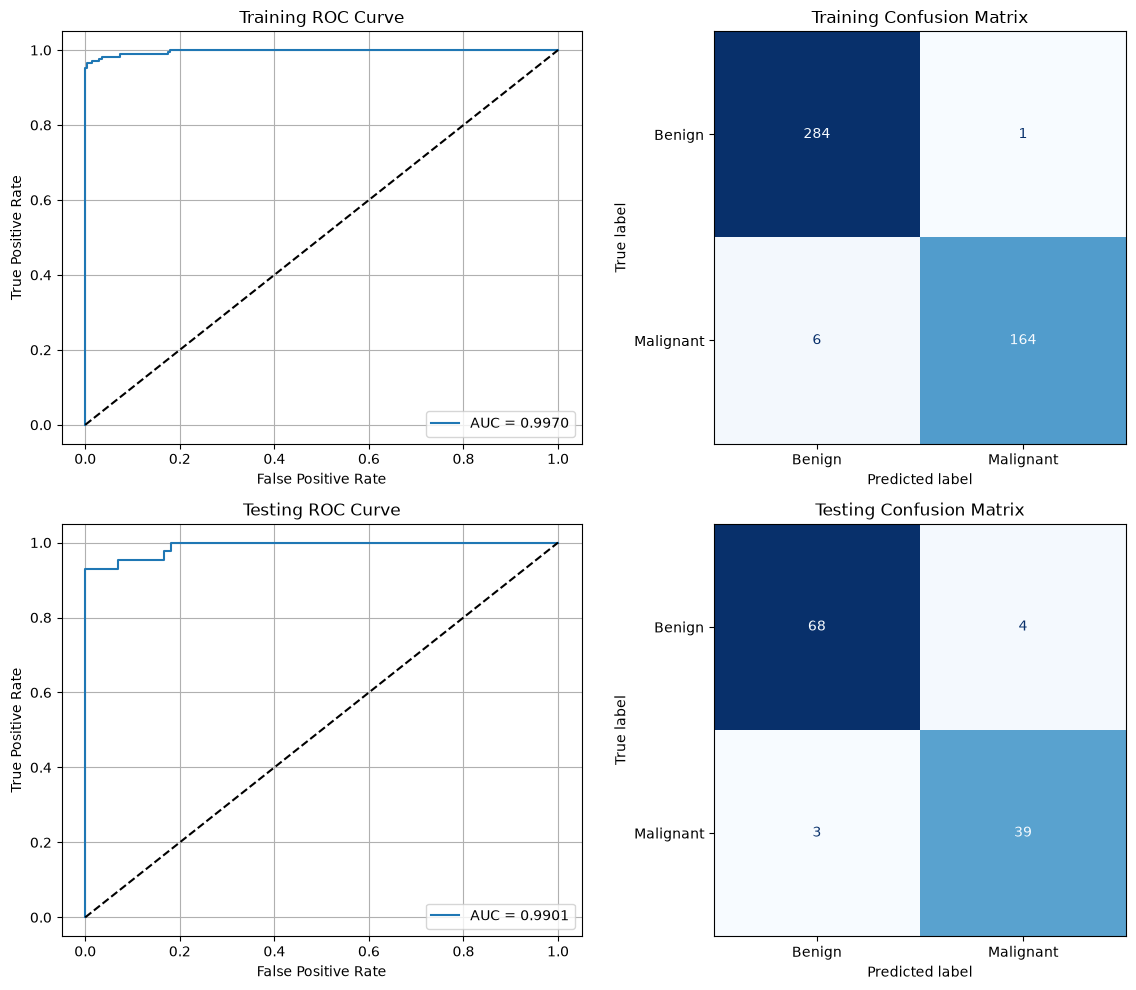

In [13]:
# ROC curves and confusion matrices for semi-supervised learning

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (name, X_data, y_data) in enumerate([
    ("Training", X_train, y_train),
    ("Testing", X_test, y_test)
]):
    y_pred = semi_model.predict(X_data)
    y_score = semi_model.decision_function(X_data)

    # ROC curve
    fpr, tpr, _ = roc_curve(y_data, y_score)
    auc_value = roc_auc_score(y_data, y_score)

    axes[i, 0].plot(
        fpr, tpr,
        label=f"AUC = {auc_value:.4f}"
    )
    axes[i, 0].plot([0, 1], [0, 1], "k--")
    axes[i, 0].set_title(f"{name} ROC Curve")
    axes[i, 0].set_xlabel("False Positive Rate")
    axes[i, 0].set_ylabel("True Positive Rate")
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    # Confusion matrix
    cm = confusion_matrix(y_data, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(
        ax=axes[i, 1],
        cmap="Blues",
        colorbar=False
    )

    axes[i, 1].set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

##### Monte Carlo Simulation (30 Runs)

In [14]:
# Monte Carlo Simulation for Semi-Supervised Learning

M = 30

semi_train_results = []
semi_test_results = []
semi_best_C = []

for run in range(M):

    # 1. Random stratified train/test split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=run
    )

    # 2. Split training data into labeled and unlabeled sets
    X_lab, X_unlab, y_lab, _ = train_test_split(
        X_tr, y_tr,
        test_size=0.5,
        stratify=y_tr,
        random_state=run
    )

    # 3. Initial SVM with 5-fold cross-validation
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=run
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__C": np.logspace(-3, 3, 13)
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_lab, y_lab)

    model = grid.best_estimator_
    best_C = grid.best_params_["svm__C"]
    semi_best_C.append(best_C)

    # 4. Iterative self-training
    X_lab_current = X_lab.copy()
    y_lab_current = y_lab.copy()
    X_unlab_current = X_unlab.copy()

    while len(X_unlab_current) > 0:

        # Find the point farthest from the decision boundary
        scores = model.decision_function(X_unlab_current)
        idx = np.argmax(np.abs(scores))

        # Predict pseudo-label
        selected_X = X_unlab_current[idx:idx+1]
        pseudo_label = model.predict(selected_X)

        # Add the sample to labeled data
        X_lab_current = np.vstack([
            X_lab_current, selected_X
        ])

        y_lab_current = np.concatenate([
            y_lab_current, pseudo_label
        ])

        # Remove selected sample from unlabeled pool
        X_unlab_current = np.delete(
            X_unlab_current, idx, axis=0
        )

        # Retrain SVM with the expanded labeled data
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", LinearSVC(
                penalty="l1",
                dual=False,
                C=best_C,
                max_iter=20000,
                random_state=42
            ))
        ])

        model.fit(X_lab_current, y_lab_current)

    # 5. Evaluate using TRUE labels
    semi_train_results.append(
        evaluate_model(model, X_tr, y_tr)
    )

    semi_test_results.append(
        evaluate_model(model, X_te, y_te)
    )

    print(f"Run {run + 1}/{M} completed")

# 6. Calculate average performance
semi_train_avg = pd.DataFrame(
    semi_train_results
).mean()

semi_test_avg = pd.DataFrame(
    semi_test_results
).mean()

semi_summary = pd.DataFrame({
    "Training": semi_train_avg,
    "Testing": semi_test_avg
}).T

print("\nAverage Semi-Supervised Performance over 30 Runs:")
display(semi_summary.round(4))

print("\nPenalty parameter C selected by 5-fold CV (count over 30 runs):")
print(pd.Series(semi_best_C).value_counts().sort_index().rename("count"))

print("\nRun 1 test metrics:",
      {k: round(v, 4) for k, v in semi_test_results[0].items()})

Run 1/30 completed


Run 2/30 completed


Run 3/30 completed


Run 4/30 completed


Run 5/30 completed


Run 6/30 completed


... (22 outputs left out)

Run 29/30 completed


Run 30/30 completed

Average Semi-Supervised Performance over 30 Runs:


,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9782,0.9815,0.9602,0.9706,0.9949
Testing,0.9643,0.9728,0.9302,0.9505,0.9916



Penalty parameter C selected by 5-fold CV (count over 30 runs):
0.031623       3
0.100000       6
0.316228      14
1.000000       4
3.162278       2
316.227766     1
Name: count, dtype: int64

Run 1 test metrics: {'Accuracy': 0.9386, 'Precision': 0.907, 'Recall': 0.9286, 'F1-score': 0.9176, 'AUC': 0.9901}


##### Results and Discussion

The semi-supervised SVM was evaluated over 30 Monte Carlo
simulations. Initially, 50% of the training data from each
class was labeled, while the remaining samples were treated
as unlabeled. The SVM iteratively assigned pseudo-labels to
the unlabeled samples farthest from the decision boundary.

The average training accuracy was 97.82%, and the average
testing accuracy was 96.43%. The average testing F1-score
was 0.9505, and the average testing AUC was 0.9916.

Compared with supervised learning, semi-supervised learning
achieved slightly lower testing accuracy (96.43% versus
96.73%) and F1-score (0.9505 versus 0.9547).

These results suggest that semi-supervised learning can
achieve competitive classification performance with fewer
initially labeled samples, although the fully supervised
SVM performed slightly better overall.

#### iii. Unsupervised Learning: K-Means Clustering

##### K-Means Clustering with Random Initialization

In [15]:
# Normalize the training and testing data

kmeans_scaler = StandardScaler()

X_train_scaled = kmeans_scaler.fit_transform(X_train)
X_test_scaled = kmeans_scaler.transform(X_test)

# K-Means clustering with random initialization
kmeans = KMeans(
    n_clusters=2,
    init="random",
    n_init=20,
    random_state=0   # same as Monte Carlo run 1
)

# Fit K-Means on the training set
train_clusters = kmeans.fit_predict(X_train_scaled)

print("Cluster distribution:", np.bincount(train_clusters))
print("Cluster centers shape:", kmeans.cluster_centers_.shape)
print("Inertia:", kmeans.inertia_)

Cluster distribution: [310 145]
Cluster centers shape: (2, 30)
Inertia: 9216.676891981773


##### A. Random Initialization and Avoiding Local Minima

K-means only converges to a *local* minimum of its objective (the within-cluster sum of squared distances, `inertia`), and the result depends on the random initial centers. To check this, k-means is run 30 times on the training set, each time with a **single random initialization** (`init="random"`, `n_init=1`), and the final objective values are compared.

Lowest inertia over 30 random initializations: 9216.6769
Initializations reaching the lowest inertia:   30/30
Inertia of the model used above (n_init=20):   9216.6769

Distinct solutions found:


,Count,Cluster_sizes
Inertia,,
9216.6769,30,"(145, 310)"


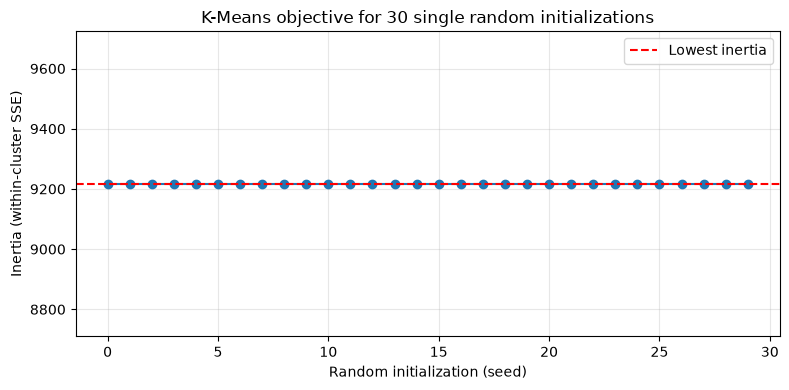

In [16]:
# Run k-means many times, each time from a single random initialization,
# and compare the objective value (inertia = within-cluster SSE)

restart_results = []

for seed in range(30):
    km = KMeans(
        n_clusters=2,
        init="random",
        n_init=1,
        random_state=seed
    )
    km.fit(X_train_scaled)

    restart_results.append({
        "Seed": seed,
        "Inertia": km.inertia_,
        "Iterations": km.n_iter_,
        "Cluster sizes": tuple(sorted(np.bincount(km.labels_, minlength=2)))
    })

restart_df = pd.DataFrame(restart_results)

best_inertia = restart_df["Inertia"].min()
n_at_best = np.isclose(restart_df["Inertia"], best_inertia, rtol=1e-6).sum()

print(f"Lowest inertia over 30 random initializations: {best_inertia:.4f}")
print(f"Initializations reaching the lowest inertia:   {n_at_best}/30")
print(f"Inertia of the model used above (n_init=20):   {kmeans.inertia_:.4f}")

print("\nDistinct solutions found:")
display(
    restart_df.groupby(restart_df["Inertia"].round(4))
    .agg(Count=("Seed", "size"), Cluster_sizes=("Cluster sizes", "first"))
)

plt.figure(figsize=(8, 4))
plt.plot(restart_df["Seed"], restart_df["Inertia"], "o-")
plt.axhline(best_inertia, color="r", linestyle="--", label="Lowest inertia")
plt.xlabel("Random initialization (seed)")
plt.ylabel("Inertia (within-cluster SSE)")
plt.title("K-Means objective for 30 single random initializations")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**How do we make sure that k-means was not trapped in a local minimum?**

K-means (Lloyd's algorithm) is only guaranteed to converge to a *local* minimum of the within-cluster sum of squares, and which minimum it reaches depends on the random initial centers. To guard against a poor local minimum we

1. initialize the centers randomly (`init="random"`) and restart the algorithm many times (`n_init=20` in every run, including every Monte Carlo run),
2. keep the restart with the lowest objective value (inertia), which `KMeans` does automatically over its `n_init` restarts, and
3. check that independent random restarts agree.

In the check above, **all 30 single random initializations converged to the same objective value (inertia ≈ 9216.68) with the same cluster sizes (145 / 310)**, and this equals the inertia of the model fitted with `n_init=20`. Since no random start found a lower objective and all of them reached the same solution, it is very unlikely that the chosen clustering is a poor local minimum. (Random restarts strongly reduce, but cannot strictly rule out, the risk of a local minimum.)

##### B. Labeling Clusters by Majority Poll of the 30 Closest Points

Each cluster receives the majority label of the 30 training points closest to its center; all members of the cluster get that label.

In [17]:
# Assign class labels to clusters using majority voting

from scipy.spatial.distance import cdist

# Calculate distances from training samples to cluster centers
distances = cdist(
    X_train_scaled,
    kmeans.cluster_centers_,
    metric="euclidean"
)

cluster_labels = {}

for cluster_id in range(2):

    # Find the 30 closest training points to this center
    nearest_indices = np.argsort(
        distances[:, cluster_id]
    )[:30]

    # Get their true labels
    nearest_true_labels = y_train[nearest_indices]

    # Majority voting
    majority_label = np.bincount(
        nearest_true_labels,
        minlength=2
    ).argmax()

    cluster_labels[cluster_id] = majority_label

    print(f"Cluster {cluster_id}:")
    print("30 nearest points class distribution:",
          np.bincount(nearest_true_labels, minlength=2))
    print("Assigned class label:",
          "Malignant" if majority_label == 1 else "Benign")
    print()

# Convert clustering assignments into class predictions
kmeans_train_pred = np.array([
    cluster_labels[c] for c in train_clusters
])

print("Predicted training class distribution:",
      np.bincount(kmeans_train_pred, minlength=2))

Cluster 0:
30 nearest points class distribution: [30  0]
Assigned class label: Benign

Cluster 1:
30 nearest points class distribution: [ 0 30]
Assigned class label: Malignant

Predicted training class distribution: [310 145]


##### C. Classifying Test Data by Proximity to the Cluster Centers

Each test point is assigned to the nearest cluster center (`kmeans.predict`) and receives that cluster's label.

In [18]:
# Evaluate K-Means on training and testing sets

from scipy.special import softmax

# Predict test cluster assignments
test_clusters = kmeans.predict(X_test_scaled)

# Convert cluster assignments to class labels
kmeans_test_pred = np.array([
    cluster_labels[c] for c in test_clusters
])

# Get distances to cluster centers
train_distances = kmeans.transform(X_train_scaled)
test_distances = kmeans.transform(X_test_scaled)

# Convert negative distances into probabilities
train_probs = softmax(-train_distances, axis=1)
test_probs = softmax(-test_distances, axis=1)

# Identify the cluster corresponding to malignant class
malignant_cluster = [
    c for c, label in cluster_labels.items() if label == 1
][0]

# Use malignant cluster probabilities as positive-class scores
kmeans_train_scores = train_probs[:, malignant_cluster]
kmeans_test_scores = test_probs[:, malignant_cluster]

# Evaluation function
def evaluate_clustering(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "AUC": roc_auc_score(y_true, y_score)
    }

# Calculate metrics
kmeans_train_metrics = evaluate_clustering(
    y_train, kmeans_train_pred, kmeans_train_scores
)

kmeans_test_metrics = evaluate_clustering(
    y_test, kmeans_test_pred, kmeans_test_scores
)

# Display results
kmeans_results_df = pd.DataFrame(
    [kmeans_train_metrics, kmeans_test_metrics],
    index=["Training", "Testing"]
)

print("K-Means Classification Performance:")
display(kmeans_results_df.round(4))

K-Means Classification Performance:


,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9099,0.9448,0.8059,0.8698,0.9767
Testing,0.8772,0.8333,0.8333,0.8333,0.9593


##### ROC Curves and Confusion Matrices (Monte Carlo run 1)

Following footnote 2, the distances to the two centers are passed through a softmax to obtain a probability-like score for the malignant cluster.

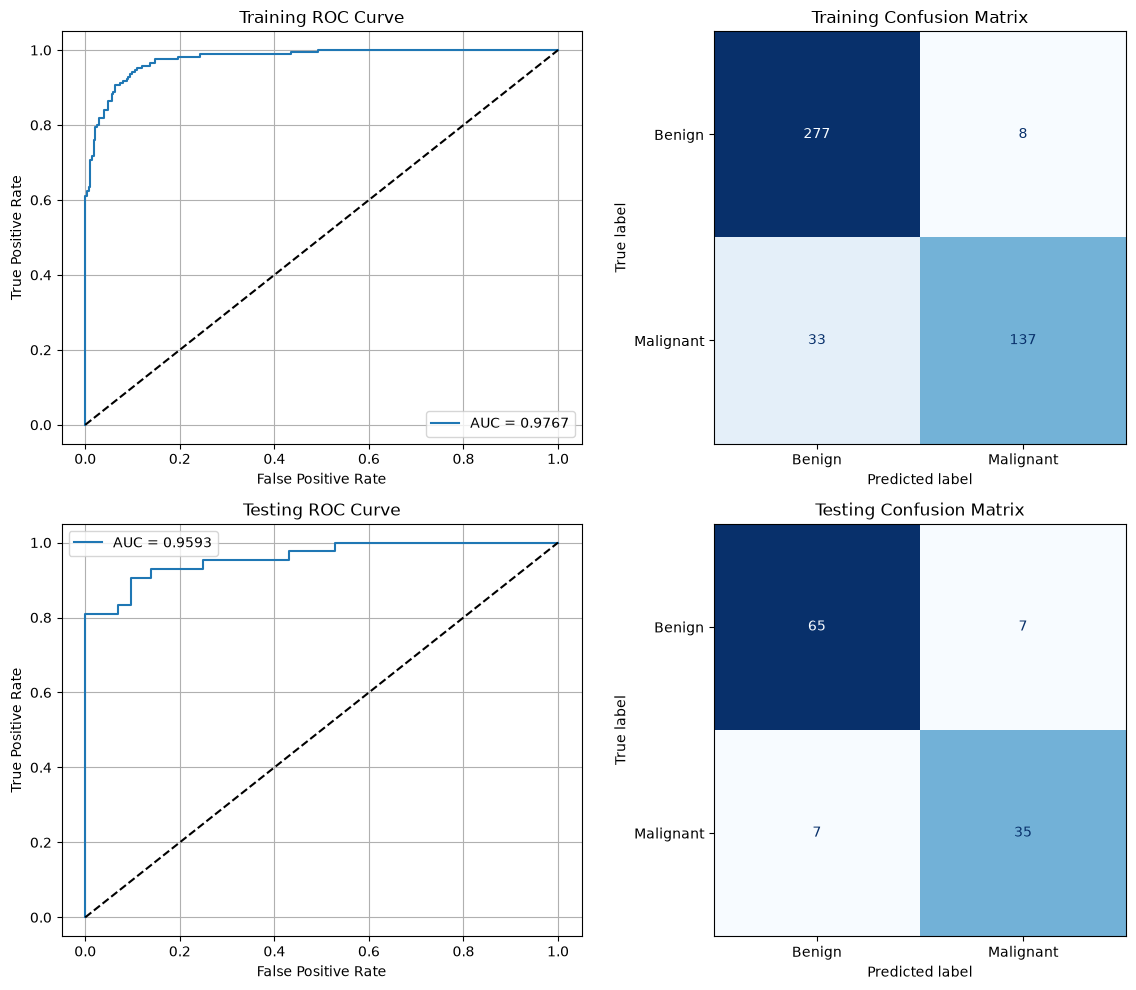

In [19]:
# ROC curves and confusion matrices for K-Means

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (name, y_true, y_pred, y_score) in enumerate([
    ("Training", y_train, kmeans_train_pred, kmeans_train_scores),
    ("Testing", y_test, kmeans_test_pred, kmeans_test_scores)
]):

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc_value = roc_auc_score(y_true, y_score)

    axes[i, 0].plot(
        fpr, tpr,
        label=f"AUC = {auc_value:.4f}"
    )

    axes[i, 0].plot([0, 1], [0, 1], "k--")
    axes[i, 0].set_title(f"{name} ROC Curve")
    axes[i, 0].set_xlabel("False Positive Rate")
    axes[i, 0].set_ylabel("True Positive Rate")
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(
        ax=axes[i, 1],
        cmap="Blues",
        colorbar=False
    )

    axes[i, 1].set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

##### Monte Carlo Simulation (30 Runs)

In [20]:
# Monte Carlo Simulation for K-Means

M = 30

kmeans_train_results = []
kmeans_test_results = []

for run in range(M):

    # 1. Random stratified train/test split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=run
    )

    # 2. Normalize data
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_te_scaled = scaler.transform(X_te)

    # 3. K-Means clustering
    model = KMeans(
        n_clusters=2,
        init="random",
        n_init=20,
        random_state=run
    )

    train_clusters = model.fit_predict(X_tr_scaled)
    test_clusters = model.predict(X_te_scaled)

    # 4. Calculate distances to cluster centers
    train_distances = model.transform(X_tr_scaled)
    test_distances = model.transform(X_te_scaled)

    # 5. Majority voting using 30 nearest points
    cluster_labels = {}

    for cluster_id in range(2):

        nearest_indices = np.argsort(
            train_distances[:, cluster_id]
        )[:30]

        nearest_labels = y_tr[nearest_indices]

        majority_label = np.bincount(
            nearest_labels, minlength=2
        ).argmax()

        cluster_labels[cluster_id] = majority_label

    # 6. Convert clusters to predicted class labels
    train_pred = np.array([
        cluster_labels[c] for c in train_clusters
    ])

    test_pred = np.array([
        cluster_labels[c] for c in test_clusters
    ])

    # 7. Generate continuous scores for AUC
    train_probs = softmax(-train_distances, axis=1)
    test_probs = softmax(-test_distances, axis=1)

    malignant_clusters = [
        c for c, label in cluster_labels.items()
        if label == 1
    ]

    if len(malignant_clusters) == 1:
        malignant_cluster = malignant_clusters[0]

        train_scores = train_probs[:, malignant_cluster]
        test_scores = test_probs[:, malignant_cluster]

    else:
        # If both clusters receive the same majority label,
        # no meaningful positive-class ranking is available.
        train_scores = np.full(len(y_tr), 0.5)
        test_scores = np.full(len(y_te), 0.5)

    # 8. Evaluate training and testing performance
    kmeans_train_results.append(
        evaluate_clustering(y_tr, train_pred, train_scores)
    )

    kmeans_test_results.append(
        evaluate_clustering(y_te, test_pred, test_scores)
    )

    print(f"Run {run + 1}/{M} completed")

# 9. Calculate average performance
kmeans_train_avg = pd.DataFrame(
    kmeans_train_results
).mean()

kmeans_test_avg = pd.DataFrame(
    kmeans_test_results
).mean()

kmeans_summary = pd.DataFrame({
    "Training": kmeans_train_avg,
    "Testing": kmeans_test_avg
}).T

print("\nAverage K-Means Performance over 30 Runs:")
display(kmeans_summary.round(4))

print("\nRun 1 test metrics:",
      {k: round(v, 4) for k, v in kmeans_test_results[0].items()})

Run 1/30 completed
Run 2/30 completed
Run 3/30 completed
Run 4/30 completed
Run 5/30 completed


Run 6/30 completed
Run 7/30 completed
Run 8/30 completed
Run 9/30 completed
Run 10/30 completed


Run 11/30 completed
Run 12/30 completed
Run 13/30 completed
Run 14/30 completed
Run 15/30 completed


Run 16/30 completed
Run 17/30 completed
Run 18/30 completed
Run 19/30 completed
Run 20/30 completed


Run 21/30 completed
Run 22/30 completed
Run 23/30 completed


Run 24/30 completed
Run 25/30 completed
Run 26/30 completed
Run 27/30 completed
Run 28/30 completed


Run 29/30 completed
Run 30/30 completed

Average K-Means Performance over 30 Runs:


,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9103,0.9239,0.8284,0.8734,0.9749
Testing,0.9053,0.9096,0.8262,0.8647,0.9719



Run 1 test metrics: {'Accuracy': 0.8772, 'Precision': 0.8333, 'Recall': 0.8333, 'F1-score': 0.8333, 'AUC': 0.9593}


##### Results and Discussion

K-Means clustering was evaluated using 30 Monte Carlo simulations with k = 2. Random initialization with 20 restarts was used in every run; the check in part A showed that 30 independent random initializations all reach the same lowest objective value, so the solutions are not poor local minima.

Cluster labels were assigned by majority voting among the 30 nearest training samples to each cluster center, and test points were classified by their nearest cluster center.

The average training accuracy was 91.03%, while the average testing accuracy was 90.53%. The average testing F1-score was 0.8647, and the average testing AUC was 0.9719.

Compared with the supervised and semi-supervised SVMs, K-Means achieved lower classification performance, mainly because of a lower recall (0.8262). This is expected because K-Means forms clusters based on feature similarity only, without using the class labels.

However, the relatively high AUC indicates that the distance-based scores (softmax of the distances to the two centers) still rank benign and malignant samples well.

#### iv. Spectral Clustering

**What is spectral clustering?** Spectral clustering builds a similarity graph between the data points with a kernel, here the RBF kernel $A_{ij} = \exp(-\gamma \|x_i - x_j\|^2)$. It computes the eigenvectors of the normalized graph Laplacian that belong to the smallest eigenvalues, embeds every point using these eigenvectors, and clusters the points in this spectral embedding (here with k-means, `assign_labels="kmeans"`). Because clusters are defined by connectivity in the similarity graph rather than by distance to a centroid, they can be non-convex, and there is no meaningful cluster center.

##### Spectral Clustering with RBF Kernel, gamma = 1

In [21]:
# Spectral Clustering with RBF kernel

spectral = SpectralClustering(
    n_clusters=2,
    affinity="rbf",
    gamma=1.0,
    assign_labels="kmeans",
    random_state=0,
    n_init=20
)

# Fit spectral clustering on normalized training data
spectral_train_clusters = spectral.fit_predict(
    X_train_scaled
)

print(
    "Cluster distribution:",
    np.bincount(spectral_train_clusters, minlength=2)
)

print(
    "Original class distribution:",
    np.bincount(y_train)
)

print(
    "Number of clustered samples:",
    len(spectral_train_clusters)
)

Cluster distribution: [453   2]
Original class distribution: [285 170]
Number of clustered samples: 455


##### Gamma Selection for Balanced Spectral Clustering

With gamma = 1 almost all points fall into one cluster, which does not resemble the class balance. Following the assignment, we search a fine log-spaced grid of gamma values ($10^{-5}$ to $10^{-1.5}$, 36 values) and choose the gamma whose two cluster sizes are closest to the class sizes in the training set (p malignant and n benign samples). If several gammas give the same best balance, the largest one is used.

In [22]:
# Fine search for a gamma whose cluster sizes match the class sizes

gamma_grid = np.logspace(-5, -1.5, 36)


def select_balanced_gamma(X_scaled, y_true, gammas, random_state):
    """Return the gamma whose two cluster sizes are closest to the
    class sizes (p, n), together with the full search table."""
    target = np.sort(np.bincount(y_true, minlength=2))
    rows = []

    for g in gammas:
        sc = SpectralClustering(
            n_clusters=2,
            affinity="rbf",
            gamma=g,
            assign_labels="kmeans",
            random_state=random_state,
            n_init=20
        )
        sizes = np.sort(np.bincount(sc.fit_predict(X_scaled), minlength=2))

        rows.append({
            "Gamma": g,
            "Smaller cluster": sizes[0],
            "Larger cluster": sizes[1],
            "Size gap": abs(int(sizes[0]) - int(target[0]))
        })

    table = pd.DataFrame(rows)

    # Several gammas may give the same best balance (for very small gamma the
    # solution no longer changes); take the largest of them
    best_gap = table["Size gap"].min()
    best_gamma = table.loc[table["Size gap"] == best_gap, "Gamma"].max()

    return best_gamma, table


selected_gamma, gamma_df = select_balanced_gamma(
    X_train_scaled, y_train, gamma_grid, random_state=0
)

print("Target cluster sizes (class sizes p, n):",
      np.sort(np.bincount(y_train)))
display(gamma_df.round({"Gamma": 6}))
print("Selected gamma:", selected_gamma)

Target cluster sizes (class sizes p, n): [170 285]


,Gamma,Smaller cluster,Larger cluster,Size gap
0,0.000010,147,308,23
1,0.000013,147,308,23
2,0.000016,147,308,23
3,0.000020,147,308,23
4,0.000025,147,308,23
5,0.000032,147,308,23
6,0.000040,147,308,23
7,0.000050,147,308,23
8,0.000063,147,308,23
9,0.000079,147,308,23


Selected gamma: 0.00019952623149688788


##### Spectral Clustering with the Selected Gamma (`fit_predict` on the whole training set)

In [23]:
# Spectral Clustering with selected gamma

spectral = SpectralClustering(
    n_clusters=2,
    affinity="rbf",
    gamma=selected_gamma,
    assign_labels="kmeans",
    random_state=0,
    n_init=20
)

spectral_train_clusters = spectral.fit_predict(
    X_train_scaled
)

print(
    "Selected gamma:", selected_gamma
)

print(
    "Cluster distribution:",
    np.bincount(spectral_train_clusters, minlength=2)
)

print(
    "Original class distribution:",
    np.bincount(y_train)
)

Selected gamma: 0.00019952623149688788
Cluster distribution: [308 147]
Original class distribution: [285 170]


##### Assigning Spectral Cluster Labels Using Majority Voting

Spectral clustering has no cluster centers, so (following footnote 3) each cluster is labeled by a majority poll over **all training points** in that cluster.

In [24]:
# Assign class labels using majority voting

spectral_cluster_labels = {}

for cluster_id in range(2):

    # Get all training samples belonging to this cluster
    cluster_indices = np.where(
        spectral_train_clusters == cluster_id
    )[0]

    # Read their true labels
    cluster_true_labels = y_train[cluster_indices]

    # Majority voting
    label_counts = np.bincount(
        cluster_true_labels,
        minlength=2
    )

    majority_label = np.argmax(label_counts)

    spectral_cluster_labels[cluster_id] = majority_label

    print(f"Cluster {cluster_id}:")
    print("Number of samples:", len(cluster_indices))
    print("True label distribution:", label_counts)
    print(
        "Assigned label:",
        "Malignant" if majority_label == 1 else "Benign"
    )
    print()

# Convert cluster assignments into predicted labels
spectral_train_pred = np.array([
    spectral_cluster_labels[c]
    for c in spectral_train_clusters
])

print(
    "Predicted training class distribution:",
    np.bincount(spectral_train_pred, minlength=2)
)

# Fraction of malignant training points in each cluster
# (used as the score when varying the majority-polling threshold for ROC)
spectral_cluster_frac = {
    c: y_train[spectral_train_clusters == c].mean() for c in range(2)
}
print("Malignant fraction per cluster:",
      {c: round(f, 4) for c, f in spectral_cluster_frac.items()})

Cluster 0:
Number of samples: 308
True label distribution: [276  32]
Assigned label: Benign

Cluster 1:
Number of samples: 147
True label distribution: [  9 138]
Assigned label: Malignant

Predicted training class distribution: [308 147]
Malignant fraction per cluster: {0: np.float64(0.1039), 1: np.float64(0.9388)}


##### Classifying Test Data with `fit_predict` and Evaluation

Test points are **not** labeled by their proximity to a cluster center. Spectral clustering has no `predict` method for unseen points, so the test data are labeled with `fit_predict`: the standardized training and test points are clustered together with the same gamma, each resulting cluster is labeled by the majority poll of the **training** points it contains (test labels are never used), and every test point receives the label of its cluster.

For the ROC curves we follow footnote 3 and vary the threshold $t$ of the majority poll: the score of a point is the fraction of malignant training points in its cluster, and a cluster is called malignant if this fraction is at least $t$. Sweeping $t$ from 0 to 1 traces the ROC curve.

In [25]:
# Classify test data using fit_predict on training + test data

def spectral_fit_predict_labels(X_tr_s, y_tr, X_te_s, gamma, random_state):
    """Cluster training and test data together with fit_predict and label
    each cluster by the majority poll of the training points it contains."""
    sc = SpectralClustering(
        n_clusters=2,
        affinity="rbf",
        gamma=gamma,
        assign_labels="kmeans",
        random_state=random_state,
        n_init=20
    )
    all_clusters = sc.fit_predict(np.vstack([X_tr_s, X_te_s]))

    tr_clusters = all_clusters[:len(X_tr_s)]
    te_clusters = all_clusters[len(X_tr_s):]

    labels, frac = {}, {}
    for c in range(2):
        members = y_tr[tr_clusters == c]
        if len(members) > 0:
            frac[c] = members.mean()
            labels[c] = int(np.bincount(members, minlength=2).argmax())
        else:
            frac[c], labels[c] = 0.0, 0

    te_pred = np.array([labels[c] for c in te_clusters])
    te_score = np.array([frac[c] for c in te_clusters])

    return te_pred, te_score, te_clusters


# Scores for ROC: malignant fraction of the cluster each point belongs to
spectral_train_scores = np.array([
    spectral_cluster_frac[c] for c in spectral_train_clusters
])

spectral_test_pred, spectral_test_scores, spectral_test_clusters = (
    spectral_fit_predict_labels(
        X_train_scaled, y_train, X_test_scaled,
        selected_gamma, random_state=0
    )
)

print("Test cluster distribution:",
      np.bincount(spectral_test_clusters, minlength=2))

spectral_train_metrics = evaluate_clustering(
    y_train, spectral_train_pred, spectral_train_scores
)

spectral_test_metrics = evaluate_clustering(
    y_test, spectral_test_pred, spectral_test_scores
)

spectral_results_df = pd.DataFrame(
    [spectral_train_metrics, spectral_test_metrics],
    index=["Training", "Testing"]
)

print("Spectral Clustering Performance:")
display(spectral_results_df.round(4))

Test cluster distribution: [71 43]
Spectral Clustering Performance:


,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9099,0.9388,0.8118,0.8707,0.8901
Testing,0.9035,0.8605,0.8810,0.8706,0.8988


##### ROC Curves and Confusion Matrices (Monte Carlo run 1)

Because every point in a cluster has the same score, the ROC curve obtained by varying the polling threshold has only a few corner points.

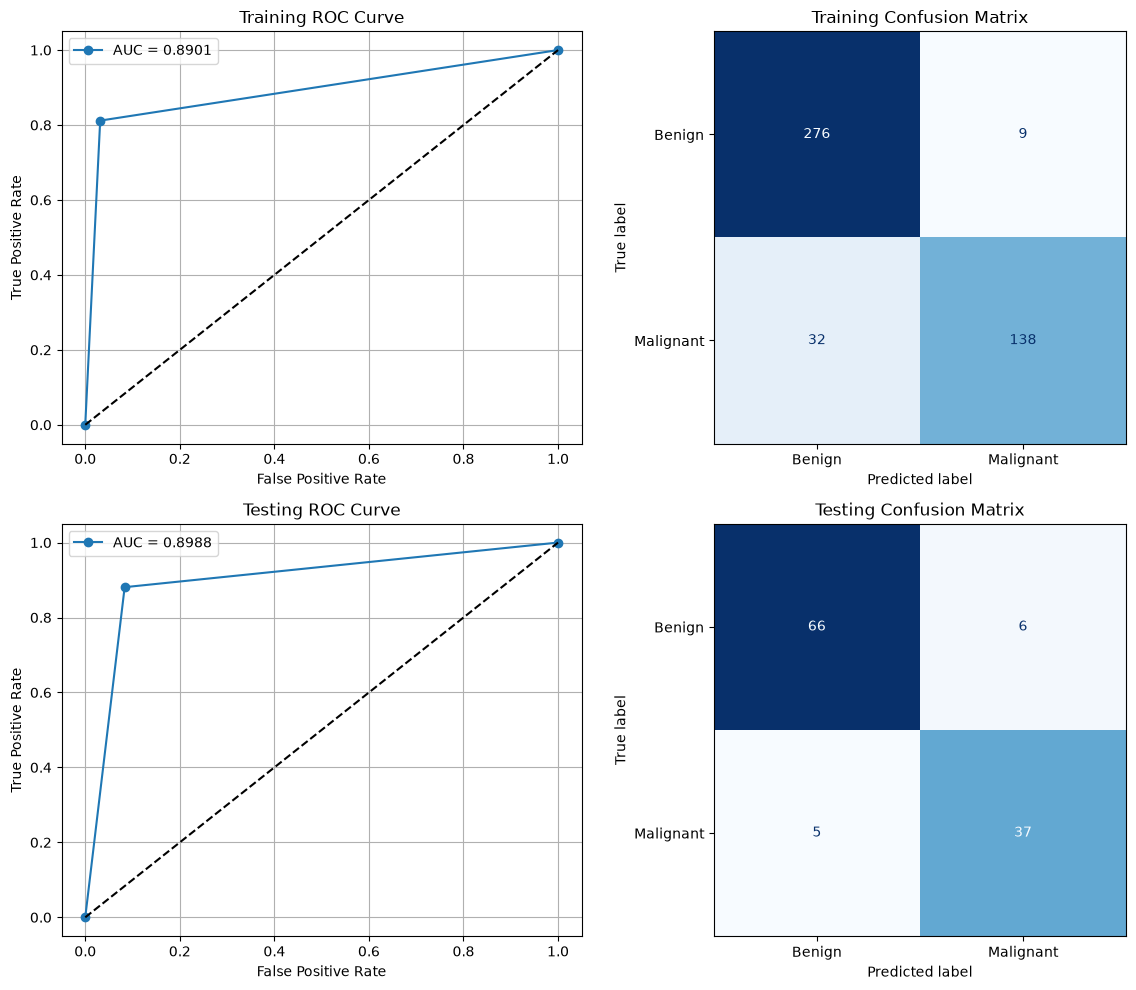

In [26]:
# ROC curves and confusion matrices for Spectral Clustering

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (name, y_true, y_pred, y_score) in enumerate([
    ("Training", y_train, spectral_train_pred, spectral_train_scores),
    ("Testing", y_test, spectral_test_pred, spectral_test_scores)
]):

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc_value = roc_auc_score(y_true, y_score)

    axes[i, 0].plot(
        fpr, tpr, marker="o",
        label=f"AUC = {auc_value:.4f}"
    )

    axes[i, 0].plot([0, 1], [0, 1], "k--")
    axes[i, 0].set_title(f"{name} ROC Curve")
    axes[i, 0].set_xlabel("False Positive Rate")
    axes[i, 0].set_ylabel("True Positive Rate")
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(
        ax=axes[i, 1],
        cmap="Blues",
        colorbar=False
    )

    axes[i, 1].set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

##### Monte Carlo Simulation (30 Runs)

In [27]:
# Monte Carlo Simulation for Spectral Clustering

M = 30

spectral_train_results = []
spectral_test_results = []
spectral_run_info = []

for run in range(M):

    # 1. Stratified train/test split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=run
    )

    # 2. Standardize features
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_te_scaled = scaler.transform(X_te)

    # 3. Choose gamma so that the cluster sizes match the class sizes
    gamma_run, _ = select_balanced_gamma(
        X_tr_scaled, y_tr, gamma_grid, random_state=run
    )

    # 4. Spectral clustering (fit_predict) on the whole training set
    model = SpectralClustering(
        n_clusters=2,
        affinity="rbf",
        gamma=gamma_run,
        assign_labels="kmeans",
        random_state=run,
        n_init=20
    )

    train_clusters = model.fit_predict(X_tr_scaled)

    # 5. Majority poll over all training points of each cluster
    cluster_labels, cluster_frac = {}, {}

    for c in range(2):
        members = y_tr[train_clusters == c]
        if len(members) > 0:
            cluster_frac[c] = members.mean()
            cluster_labels[c] = int(np.bincount(members, minlength=2).argmax())
        else:
            cluster_frac[c], cluster_labels[c] = 0.0, 0

    train_pred = np.array([cluster_labels[c] for c in train_clusters])
    train_scores = np.array([cluster_frac[c] for c in train_clusters])

    # 6. Test data: fit_predict on training + test data
    test_pred, test_scores, _ = spectral_fit_predict_labels(
        X_tr_scaled, y_tr, X_te_scaled, gamma_run, random_state=run
    )

    # 7. Evaluate performance
    spectral_train_results.append(
        evaluate_clustering(y_tr, train_pred, train_scores)
    )

    spectral_test_results.append(
        evaluate_clustering(y_te, test_pred, test_scores)
    )

    sizes = np.sort(np.bincount(train_clusters, minlength=2))
    spectral_run_info.append({
        "Run": run + 1,
        "Gamma": gamma_run,
        "Smaller cluster": sizes[0],
        "Larger cluster": sizes[1],
        "Size gap": abs(int(sizes[0]) - int(y_tr.sum()))
    })

    print(f"Run {run + 1}/{M} completed (gamma = {gamma_run:.6f})")

# 8. Average results
spectral_train_avg = pd.DataFrame(spectral_train_results).mean()
spectral_test_avg = pd.DataFrame(spectral_test_results).mean()

spectral_summary = pd.DataFrame({
    "Training": spectral_train_avg,
    "Testing": spectral_test_avg
}).T

print("\nAverage Spectral Clustering Performance over 30 Runs:")
display(spectral_summary.round(4))

# 9. Selected gamma and cluster balance in each run
spectral_info_df = pd.DataFrame(spectral_run_info)

print("\nClass sizes in every training set: p =", int(y_tr.sum()),
      "malignant, n =", int(len(y_tr) - y_tr.sum()), "benign")
print("Selected gamma and cluster sizes in each run:")
display(spectral_info_df.round({"Gamma": 6}))
print("Average |smaller cluster - p|:",
      round(spectral_info_df["Size gap"].mean(), 2))

print("\nRun 1 test metrics:",
      {k: round(v, 4) for k, v in spectral_test_results[0].items()})

Run 1/30 completed (gamma = 0.000200)


Run 2/30 completed (gamma = 0.000794)


Run 3/30 completed (gamma = 0.000200)


Run 4/30 completed (gamma = 0.000126)


Run 5/30 completed (gamma = 0.000794)


Run 6/30 completed (gamma = 0.001585)


... (24 outputs left out)

,Accuracy,Precision,Recall,F1-score,AUC
Training,0.9084,0.9201,0.8269,0.8709,0.8920
Testing,0.9061,0.9173,0.8214,0.8651,0.8885



Class sizes in every training set: p = 170 malignant, n = 285 benign
Selected gamma and cluster sizes in each run:


,Run,Gamma,Smaller cluster,Larger cluster,Size gap
0,1,0.000200,147,308,23
1,2,0.000794,152,303,18
2,3,0.000200,156,299,14
3,4,0.000126,153,302,17
4,5,0.000794,153,302,17
5,6,0.001585,159,296,11
6,7,0.000794,157,298,13
7,8,0.001995,153,302,17
8,9,0.001259,151,304,19
9,10,0.000794,155,300,15


Average |smaller cluster - p|: 17.2

Run 1 test metrics: {'Accuracy': 0.9035, 'Precision': 0.8605, 'Recall': 0.881, 'F1-score': 0.8706, 'AUC': 0.8988}


##### Results and Discussion

Spectral clustering was evaluated over 30 Monte Carlo runs with an RBF kernel. With gamma = 1 the similarity graph is almost disconnected and nearly all points fall into one cluster (453 vs. 2). Therefore, in every run gamma was chosen from a fine grid so that the cluster sizes are as close as possible to the class sizes (p = 170 malignant, n = 285 benign). An exact match was not achievable: for small gamma the clustering stops changing, while larger gamma values make the clusters more unbalanced. The best achievable smaller cluster had 147–160 points, on average 17.2 points away from p.

Training points were labeled by a majority poll over all training points in each cluster. Test points were labeled with `fit_predict` on the combined training and test data, using the majority poll of the training points in each cluster; no proximity to cluster centers was used.

The average training accuracy was 90.84%, and the average testing accuracy was 90.61%. The average testing precision, recall and F1-score were 0.9173, 0.8214 and 0.8651. The small gap between training and testing performance shows that the `fit_predict`-based labeling of the test data works as well as the clustering of the training data. The results are very close to those of k-means (testing accuracy 90.53%, F1-score 0.8647). This is plausible, because with such a small gamma the RBF similarity changes smoothly with distance and spectral clustering finds nearly the same two groups as k-means.

The average testing AUC (0.8885) is lower than for k-means (0.9719). This comes from how the ROC curve is obtained (footnote 3): all points in a cluster share the same score (the malignant fraction of the cluster), so the ROC curve has only one interior corner and cannot reflect any ranking within a cluster, whereas the softmax of distances used for k-means gives a continuous score. The AUC values of the two clustering methods are therefore not directly comparable.

#### v. Comparison of Learning Methods

##### Average Training and Testing Performance

In [28]:
# Compare the four learning methods (average over 30 runs)

comparison_train_df = pd.DataFrame({
    "Supervised SVM": supervised_train_avg,
    "Semi-Supervised SVM": semi_train_avg,
    "K-Means": kmeans_train_avg,
    "Spectral Clustering": spectral_train_avg
}).T

comparison_df = pd.DataFrame({
    "Supervised SVM": supervised_test_avg,
    "Semi-Supervised SVM": semi_test_avg,
    "K-Means": kmeans_test_avg,
    "Spectral Clustering": spectral_test_avg
}).T

print("Average Training Performance (30 Runs):")
display(comparison_train_df.round(4))

print("Average Testing Performance (30 Runs):")
display(comparison_df.round(4))

Average Training Performance (30 Runs):


,Accuracy,Precision,Recall,F1-score,AUC
Supervised SVM,0.9855,0.9912,0.9698,0.9804,0.9972
Semi-Supervised SVM,0.9782,0.9815,0.9602,0.9706,0.9949
K-Means,0.9103,0.9239,0.8284,0.8734,0.9749
Spectral Clustering,0.9084,0.9201,0.8269,0.8709,0.8920


Average Testing Performance (30 Runs):


,Accuracy,Precision,Recall,F1-score,AUC
Supervised SVM,0.9673,0.9711,0.9397,0.9547,0.9932
Semi-Supervised SVM,0.9643,0.9728,0.9302,0.9505,0.9916
K-Means,0.9053,0.9096,0.8262,0.8647,0.9719
Spectral Clustering,0.9061,0.9173,0.8214,0.8651,0.8885


##### Results and Discussion

The four learning methods were compared using their average performance over 30 Monte Carlo simulations (tables above).

**Supervised SVM** achieved the best performance, with a testing accuracy of 96.73%, an F1-score of 0.9547 and an AUC of 0.9932.

**Semi-supervised SVM** (only half of the training labels) performed almost as well: 96.43% accuracy, F1-score 0.9505 and AUC 0.9916, only 0.3 percentage points below the supervised SVM. Self-training recovers most of the value of the missing labels, because the data are nearly linearly separable and the points pseudo-labeled first (farthest from the boundary) are almost always labeled correctly.

**Unsupervised methods** performed clearly worse: K-Means reached 90.53% accuracy (F1-score 0.8647) and spectral clustering 90.61% (F1-score 0.8651), about 6 percentage points below the SVMs. The difference comes mainly from the recall (about 0.82–0.83 instead of about 0.94): a cluster boundary found without labels assigns a group of malignant tumors that resemble benign ones to the benign cluster.

For the SVMs, training performance is about 1.5 percentage points above testing performance, while the clustering methods have almost identical training and testing performance, because the labels are only used in the majority poll.

Overall, the results agree with the expectation: supervised learning on the full training set works best, semi-supervised learning with half of the labels is only slightly worse, and unsupervised learning underperforms. The AUC of spectral clustering is not directly comparable with the other methods (see iv).

## 2. Active Learning Using Support Vector Machines

### 2(a) Banknote Authentication Dataset

In [29]:
# Load Banknote Authentication dataset

banknote_df = pd.read_csv(
    "data_banknote_authentication.txt",
    header=None
)

print("Dataset shape:", banknote_df.shape)
display(banknote_df.head())

print("Class distribution:")
print(banknote_df.iloc[:, -1].value_counts())

Dataset shape: (1372, 5)


,0,1,2,3,4
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Class distribution:
4
0    762
1    610
Name: count, dtype: int64


##### Splitting the Dataset into Training and Testing Sets

In [30]:
# Separate features and labels
X_banknote = banknote_df.iloc[:, :-1].values
y_banknote = banknote_df.iloc[:, -1].values.astype(int)

# Randomly split into 900 training and 472 testing samples
X_bank_train, X_bank_test, y_bank_train, y_bank_test = train_test_split(
    X_banknote,
    y_banknote,
    train_size=900,
    test_size=472,
    stratify=y_banknote,
    random_state=42
)

print("Training set:", X_bank_train.shape)
print("Testing set:", X_bank_test.shape)

print(
    "Training class distribution:",
    np.bincount(y_bank_train)
)

print(
    "Testing class distribution:",
    np.bincount(y_bank_test)
)

Training set: (900, 4)
Testing set: (472, 4)
Training class distribution: [500 400]
Testing class distribution: [262 210]


### 2(b) Passive and Active Learning

The initial pool of 10 points is drawn completely at random from the training set; following footnote 5, it is redrawn only if all 10 points belong to the same class. Since a small pool may contain only one or two points of a class, some CV folds may have training data from a single class. Such a fit fails for every value of $C$ and receives a score of 0 (`error_score=0.0`), so the ranking of the $C$ values is decided by the remaining folds.

Passive and active learning use the same random seeds (`42 + run`), so in each Monte Carlo run both procedures start from the same initial pool.

#### i. Passive Learning

##### Initial Training Pool Selection

In [31]:
# Select an initial pool of 10 training samples

rng = np.random.default_rng(42)

all_indices = np.arange(len(y_bank_train))

while True:
    initial_indices = rng.choice(
        all_indices,
        size=10,
        replace=False
    )

    initial_labels = y_bank_train[initial_indices]

    # Redraw only if all 10 points come from one class (footnote 5)
    if np.all(np.bincount(initial_labels, minlength=2) > 0):
        break

X_pool = X_bank_train[initial_indices]
y_pool = y_bank_train[initial_indices]

# Remaining samples
remaining_indices = np.setdiff1d(
    all_indices,
    initial_indices
)

print("Initial pool shape:", X_pool.shape)
print("Initial class distribution:", np.bincount(y_pool))
print("Remaining samples:", len(remaining_indices))

Initial pool shape: (10, 4)
Initial class distribution: [3 7]
Remaining samples: 890


##### Training the Initial L1-Penalized SVM

In [32]:
# Train the initial SVM using 10 labeled samples

passive_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        penalty="l1",
        dual=False,
        max_iter=20000,
        random_state=42
    ))
])

# Define the penalty parameter grid
passive_param_grid = {
    "svm__C": np.logspace(-3, 3, 13)
}

# 5-fold cross-validation
passive_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

passive_grid = GridSearchCV(
    estimator=passive_pipeline,
    param_grid=passive_param_grid,
    cv=passive_cv,
    scoring="accuracy",
    error_score=0.0,
    n_jobs=-1
)

# Train the model
passive_grid.fit(X_pool, y_pool)

initial_passive_svm = passive_grid.best_estimator_

# Evaluate on the test set
passive_test_pred = initial_passive_svm.predict(X_bank_test)

passive_test_error = 1 - accuracy_score(
    y_bank_test,
    passive_test_pred
)

print("Number of training samples:", len(y_pool))
print("Best C:", passive_grid.best_params_["svm__C"])
print("Best CV Accuracy:", passive_grid.best_score_)
print("Test Error:", passive_test_error)

Number of training samples:

 10
Best C: 3.1622776601683795
Best CV Accuracy: 1.0
Test Error: 0.10169491525423724


##### Passive Learning: Incremental Training from 10 to 900 Samples

In [33]:
# Passive Learning: One Complete Run (90 SVMs)

rng = np.random.default_rng(42)

all_indices = np.arange(len(y_bank_train))

# Select 10 random initial samples (redraw only if all from one class)
while True:
    initial_indices = rng.choice(
        all_indices,
        size=10,
        replace=False
    )

    if np.all(np.bincount(y_bank_train[initial_indices], minlength=2) > 0):
        break

# Randomize the remaining sample order
remaining_indices = np.setdiff1d(
    all_indices,
    initial_indices
)

rng.shuffle(remaining_indices)

# Complete training order
training_order = np.concatenate([
    initial_indices,
    remaining_indices
])

passive_errors_single = []
passive_sample_sizes = []

# Train 90 SVMs using 10, 20, ..., 900 samples
for n_samples in range(10, 901, 10):

    selected_indices = training_order[:n_samples]

    X_current = X_bank_train[selected_indices]
    y_current = y_bank_train[selected_indices]

    # L1-penalized linear SVM
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])

    # 5-fold cross-validation
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__C": np.logspace(-3, 3, 13)
        },
        cv=cv,
        scoring="accuracy",
        error_score=0.0,
        n_jobs=-1
    )

    grid.fit(X_current, y_current)

    best_model = grid.best_estimator_

    # Calculate test error
    y_pred = best_model.predict(X_bank_test)

    test_error = 1 - accuracy_score(
        y_bank_test,
        y_pred
    )

    passive_errors_single.append(test_error)
    passive_sample_sizes.append(n_samples)

    if n_samples % 100 == 0 or n_samples == 10:
        print(
            f"Training samples: {n_samples}, "
            f"Test Error: {test_error:.4f}"
        )

print("\nPassive Learning completed!")
print("Number of SVMs trained:", len(passive_errors_single))
print("Number of test errors:", len(passive_errors_single))

Training samples: 10, Test Error: 0.1017


Training samples: 100, Test Error: 0.0212


Training samples: 200, Test Error: 0.0212


Training samples: 300, Test Error: 0.0106


Training samples: 400, Test Error: 0.0085


Training samples: 500, Test Error: 0.0085


Training samples: 600, Test Error: 0.0085


Training samples: 700, Test Error: 0.0085


Training samples: 800, Test Error: 0.0085


Training samples: 900, Test Error: 0.0085

Passive Learning completed!
Number of SVMs trained: 90
Number of test errors: 90


##### Monte Carlo Simulation for Passive Learning (50 Runs)

Run 1 uses the same seed (42) as the single run above.

In [34]:
# Monte Carlo Simulation for Passive Learning

M = 50
sample_sizes = np.arange(10, 901, 10)

passive_all_errors = []

for run in range(M):

    rng = np.random.default_rng(42 + run)
    all_indices = np.arange(len(y_bank_train))

    # Select 10 random initial samples (redraw only if all from one class)
    while True:
        initial_indices = rng.choice(
            all_indices,
            size=10,
            replace=False
        )

        class_counts = np.bincount(
            y_bank_train[initial_indices],
            minlength=2
        )

        if np.all(class_counts > 0):
            break

    # Randomly order the remaining samples
    remaining_indices = np.setdiff1d(
        all_indices,
        initial_indices
    )

    rng.shuffle(remaining_indices)

    training_order = np.concatenate([
        initial_indices,
        remaining_indices
    ])

    run_errors = []

    # Train 90 SVMs
    for n_samples in sample_sizes:

        selected_indices = training_order[:n_samples]

        X_current = X_bank_train[selected_indices]
        y_current = y_bank_train[selected_indices]

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=42
            ))
        ])

        cv = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid={
                "svm__C": np.logspace(-3, 3, 13)
            },
            cv=cv,
            scoring="accuracy",
            error_score=0.0,
            n_jobs=-1
        )

        grid.fit(X_current, y_current)

        best_model = grid.best_estimator_

        y_pred = best_model.predict(X_bank_test)

        test_error = 1 - accuracy_score(
            y_bank_test,
            y_pred
        )

        run_errors.append(test_error)

    passive_all_errors.append(run_errors)

    print(f"Run {run + 1}/{M} completed")

# Convert to array: 50 runs x 90 models
passive_all_errors = np.array(passive_all_errors)

# Calculate average test errors
passive_mean_errors = passive_all_errors.mean(axis=0)

print("\nPassive Learning Monte Carlo Simulation Completed!")
print("Error array shape:", passive_all_errors.shape)

passive_results_df = pd.DataFrame({
    "Training Samples": sample_sizes,
    "Average Test Error": passive_mean_errors
})

display(passive_results_df.head(10).round(4))

Run 1/50 completed


Run 2/50 completed


Run 3/50 completed


Run 4/50 completed


Run 5/50 completed


Run 6/50 completed


... (41 outputs left out)

Run 48/50 completed


Run 49/50 completed


Run 50/50 completed

Passive Learning Monte Carlo Simulation Completed!
Error array shape: (50, 90)


,Training Samples,Average Test Error
0,10,0.1311
1,20,0.0769
2,30,0.0494
3,40,0.0415
4,50,0.0367
5,60,0.0313
6,70,0.0278
7,80,0.0273
8,90,0.0270
9,100,0.0269


#### ii. Active Learning

##### Initial Training Pool Selection

In [35]:
# Select initial pool for Active Learning

rng = np.random.default_rng(42)

all_indices = np.arange(len(y_bank_train))

# Redraw only if all 10 points come from one class (footnote 5)
while True:
    initial_indices = rng.choice(
        all_indices,
        size=10,
        replace=False
    )

    class_counts = np.bincount(
        y_bank_train[initial_indices],
        minlength=2
    )

    if np.all(class_counts > 0):
        break

X_active_pool = X_bank_train[initial_indices]
y_active_pool = y_bank_train[initial_indices]

active_remaining_indices = np.setdiff1d(
    all_indices,
    initial_indices
)

print("Initial active pool:", X_active_pool.shape)
print("Class distribution:", np.bincount(y_active_pool))
print("Remaining samples:", len(active_remaining_indices))

Initial active pool: (10, 4)
Class distribution: [3 7]
Remaining samples: 890


##### Initial SVM Training and Selection of the Points Closest to the Hyperplane

For a linear SVM $f(x) = w^\top x + b$, the distance of a point $x$ to the hyperplane is $|w^\top x + b| / \|w\|$ (computed in the standardized feature space used by the SVM). The 10 remaining training points with the smallest distance are added to the pool.

In [36]:
# Train initial SVM for Active Learning

active_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        penalty="l1",
        dual=False,
        max_iter=20000,
        random_state=42
    ))
])

active_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

active_grid = GridSearchCV(
    estimator=active_pipeline,
    param_grid={
        "svm__C": np.logspace(-3, 3, 13)
    },
    cv=active_cv,
    scoring="accuracy",
    error_score=0.0,
    n_jobs=-1
)

active_grid.fit(X_active_pool, y_active_pool)

initial_active_svm = active_grid.best_estimator_

# Evaluate the initial SVM
active_pred = initial_active_svm.predict(X_bank_test)

active_test_error = 1 - accuracy_score(
    y_bank_test, active_pred
)

print("Initial training samples:", len(y_active_pool))
print("Best C:", active_grid.best_params_["svm__C"])
print("Best CV Accuracy:", active_grid.best_score_)
print("Initial Test Error:", active_test_error)

# Calculate uncertainty for all remaining samples
decision_scores = initial_active_svm.decision_function(
    X_bank_train[active_remaining_indices]
)

# Select the 10 samples closest to the decision boundary
# Distance to the hyperplane: |w.x + b| / ||w|| (in the standardized feature space)
w_norm = np.linalg.norm(initial_active_svm.named_steps["svm"].coef_)
distances_to_hyperplane = np.abs(decision_scores) / max(w_norm, 1e-12)

closest_positions = np.argsort(
    distances_to_hyperplane
)[:10]

selected_indices = active_remaining_indices[
    closest_positions
]

print("\nNumber of selected samples:", len(selected_indices))
print("Selected sample indices:", selected_indices)

print(
    "Selected class distribution:",
    np.bincount(
        y_bank_train[selected_indices],
        minlength=2
    )
)

Initial training samples: 10
Best C: 3.1622776601683795
Best CV Accuracy: 1.0
Initial Test Error: 0.10169491525423724

Number of selected samples: 10
Selected sample indices: [ 57 685 289 393 259 475 784 619 676 565]
Selected class distribution: [10  0]


##### Active Learning: Incremental Training from 10 to 900 Samples

In [37]:
# Active Learning: One Complete Run (90 SVMs)

rng = np.random.default_rng(42)
all_indices = np.arange(len(y_bank_train))

# Select 10 random initial samples (redraw only if all from one class)
while True:
    initial_indices = rng.choice(
        all_indices,
        size=10,
        replace=False
    )

    counts = np.bincount(
        y_bank_train[initial_indices],
        minlength=2
    )

    if np.all(counts > 0):
        break

pool_indices = initial_indices.copy()

remaining_indices = np.setdiff1d(
    all_indices,
    pool_indices
)

active_errors_single = []
active_sample_sizes = []

for n_samples in range(10, 901, 10):

    # Current labeled training pool
    X_current = X_bank_train[pool_indices]
    y_current = y_bank_train[pool_indices]

    # L1-penalized linear SVM
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])

    # 5-fold cross-validation
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__C": np.logspace(-3, 3, 13)
        },
        cv=cv,
        scoring="accuracy",
        error_score=0.0,
        n_jobs=-1
    )

    grid.fit(X_current, y_current)

    best_model = grid.best_estimator_

    # Calculate test error
    y_pred = best_model.predict(X_bank_test)

    test_error = 1 - accuracy_score(
        y_bank_test,
        y_pred
    )

    active_errors_single.append(test_error)
    active_sample_sizes.append(n_samples)

    if n_samples % 100 == 0 or n_samples == 10:
        print(
            f"Training samples: {n_samples}, "
            f"Test Error: {test_error:.4f}"
        )

    # No need to select more samples after reaching 900
    if n_samples == 900:
        break

    # Find the 10 samples closest to the decision boundary
    decision_scores = best_model.decision_function(
        X_bank_train[remaining_indices]
    )

    # Distance to the hyperplane: |w.x + b| / ||w|| (in the standardized feature space)
    w_norm = np.linalg.norm(best_model.named_steps["svm"].coef_)
    distances_to_hyperplane = np.abs(decision_scores) / max(w_norm, 1e-12)

    closest_positions = np.argsort(
        distances_to_hyperplane
    )[:10]

    selected_indices = remaining_indices[
        closest_positions
    ]

    # Add selected samples to the training pool
    pool_indices = np.concatenate([
        pool_indices,
        selected_indices
    ])

    # Remove selected samples from the remaining pool
    remaining_indices = np.delete(
        remaining_indices,
        closest_positions
    )

print("\nActive Learning completed!")
print("Number of SVMs trained:", len(active_errors_single))
print("Number of test errors:", len(active_errors_single))
print("Final training pool size:", len(pool_indices))
print("Remaining samples:", len(remaining_indices))

Training samples: 10, Test Error: 0.1017


Training samples: 100, Test Error: 0.0085


Training samples: 200, Test Error: 0.0127


Training samples: 300, Test Error: 0.0085


Training samples: 400, Test Error: 0.0085


Training samples: 500, Test Error: 0.0106


Training samples: 600, Test Error: 0.0085


Training samples: 700, Test Error: 0.0085


Training samples: 800, Test Error: 0.0085


Training samples: 900, Test Error: 0.0085

Active Learning completed!
Number of SVMs trained: 90
Number of test errors: 90
Final training pool size: 900
Remaining samples: 0


##### Monte Carlo Simulation for Active Learning (50 Runs)

Run 1 uses the same seed (42) as the single run above.

In [38]:
# Monte Carlo Simulation for Active Learning

M = 50
sample_sizes = np.arange(10, 901, 10)

active_all_errors = []

for run in range(M):

    rng = np.random.default_rng(42 + run)
    all_indices = np.arange(len(y_bank_train))

    # Select 10 random initial samples (redraw only if all from one class)
    while True:
        initial_indices = rng.choice(
            all_indices,
            size=10,
            replace=False
        )

        counts = np.bincount(
            y_bank_train[initial_indices],
            minlength=2
        )

        if np.all(counts > 0):
            break

    pool_indices = initial_indices.copy()

    remaining_indices = np.setdiff1d(
        all_indices,
        pool_indices
    )

    run_errors = []

    # Train 90 incrementally updated SVMs
    for n_samples in sample_sizes:

        X_current = X_bank_train[pool_indices]
        y_current = y_bank_train[pool_indices]

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=42
            ))
        ])

        cv = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid={
                "svm__C": np.logspace(-3, 3, 13)
            },
            cv=cv,
            scoring="accuracy",
            error_score=0.0,
            n_jobs=-1
        )

        grid.fit(X_current, y_current)

        best_model = grid.best_estimator_

        # Calculate test error
        y_pred = best_model.predict(X_bank_test)

        test_error = 1 - accuracy_score(
            y_bank_test,
            y_pred
        )

        run_errors.append(test_error)

        # Stop selecting new samples after 900
        if n_samples == 900:
            break

        # Select 10 samples closest to the SVM hyperplane
        decision_scores = best_model.decision_function(
            X_bank_train[remaining_indices]
        )

        # Distance to the hyperplane: |w.x + b| / ||w|| (in the standardized feature space)
        w_norm = np.linalg.norm(best_model.named_steps["svm"].coef_)
        distances_to_hyperplane = np.abs(decision_scores) / max(w_norm, 1e-12)

        closest_positions = np.argsort(
            distances_to_hyperplane
        )[:10]

        selected_indices = remaining_indices[
            closest_positions
        ]

        # Expand training pool
        pool_indices = np.concatenate([
            pool_indices,
            selected_indices
        ])

        # Remove selected samples without replacement
        remaining_indices = np.delete(
            remaining_indices,
            closest_positions
        )

    active_all_errors.append(run_errors)

    print(f"Run {run + 1}/{M} completed")

# Convert results to a 50 x 90 array
active_all_errors = np.array(active_all_errors)

# Calculate mean test error across 50 runs
active_mean_errors = active_all_errors.mean(axis=0)

print("\nActive Learning Monte Carlo Simulation Completed!")
print("Error array shape:", active_all_errors.shape)

active_results_df = pd.DataFrame({
    "Training Samples": sample_sizes,
    "Average Test Error": active_mean_errors
})

display(active_results_df.head(10).round(4))

Run 1/50 completed


Run 2/50 completed


Run 3/50 completed


Run 4/50 completed


Run 5/50 completed


Run 6/50 completed


... (41 outputs left out)

Run 48/50 completed


Run 49/50 completed


Run 50/50 completed

Active Learning Monte Carlo Simulation Completed!
Error array shape: (50, 90)


,Training Samples,Average Test Error
0,10,0.1311
1,20,0.0567
2,30,0.0299
3,40,0.0215
4,50,0.0147
5,60,0.0114
6,70,0.0097
7,80,0.0100
8,90,0.0099
9,100,0.0097


### 2(c) Learning Curves and Comparison

##### Average Test Error vs. Number of Training Instances

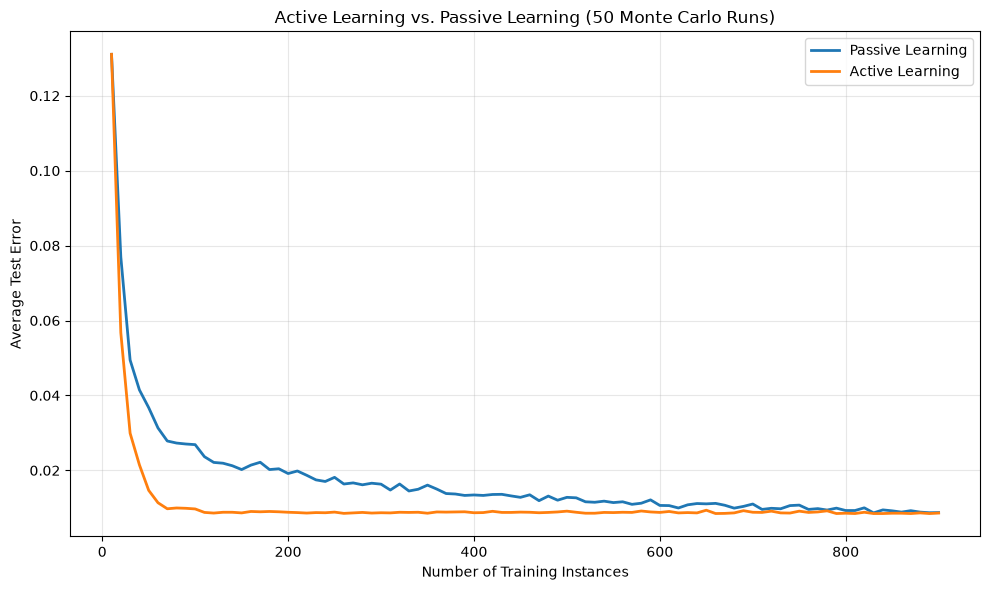

In [39]:
# Plot average test errors for Passive and Active Learning

plt.figure(figsize=(10, 6))

plt.plot(
    sample_sizes,
    passive_mean_errors,
    label="Passive Learning",
    linewidth=2
)

plt.plot(
    sample_sizes,
    active_mean_errors,
    label="Active Learning",
    linewidth=2
)

plt.xlabel("Number of Training Instances")
plt.ylabel("Average Test Error")
plt.title("Active Learning vs. Passive Learning (50 Monte Carlo Runs)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##### Results and Discussion

Passive and active learning were compared using 50 Monte Carlo simulations. In each simulation, 90 L1-penalized linear SVMs were trained using 10, 20, ..., 900 training points, with the penalty parameter selected by 5-fold cross-validation, and the error on the fixed 472-point test set was recorded. In each run both procedures start from the same random initial pool of 10 points, so both curves start at the same average test error (13.11%).

Active learning reduces the test error much faster than passive learning. With 30 training points the average test error was 2.99% for active learning versus 4.94% for passive learning; with 50 points it was 1.47% versus 3.67%; and with 100 points 0.97% versus 2.69%. Active learning reaches its plateau of about 1% test error after roughly 60–70 points, whereas passive learning still has about 2% test error at 200 points and approaches the same level only slowly.

As more training points are added, the gap between the two learners shrinks, and both curves meet at about 0.9% test error when all 900 training points are used. This is expected, because with 900 points both procedures train on exactly the same set of points (both single runs above also end at 0.85%).

**Conclusion:** selecting the points closest to the current SVM hyperplane, which are the points the classifier is least certain about and the most likely support vectors, is far more label-efficient than random sampling. On this data set, active learning reaches with about 60–100 labeled points an error that passive learning reaches only with several hundred points. Active learning is therefore most valuable when labeling data is expensive.